# 08e mcap with imu
Adds three imu channels to the version 1.1 episodes and writes the version 1.2 mcap files.

## 1. setup
Loads the config and the reports, prints the library versions and checks that every input file exists.

In [1]:
import hashlib
import heapq
import importlib.metadata as md
import json
import shutil
import subprocess
import sys
import time
import zipfile
from contextlib import ExitStack
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import yaml
from tqdm import tqdm

from mcap.reader import make_reader
from mcap.writer import CompressionType, Writer
from mcap_protobuf.schema import register_schema
from foxglove_schemas_protobuf.CompressedVideo_pb2 import CompressedVideo

try:
    import av
except ImportError:
    av = None

FORCE = False
FINAL_KEYS_ONLY = False

NB_NAME = "08e_mcap_with_imu.ipynb"
T_START = time.time()

CAMS = ["cam_high", "cam_left_wrist", "cam_right_wrist", "cam_ext"]
DEVICE = {"cam_high": "head", "cam_left_wrist": "left", "cam_right_wrist": "right"}
BODY = list(DEVICE)
VIDEO_TOPIC = {cam: f"/cameras/{cam}" for cam in CAMS}
IMU_TOPIC = {cam: f"/ego/imu/{cam}" for cam in BODY}

ROOT = Path.cwd().parent
if not (ROOT / "configs" / "config.yaml").exists():
    raise RuntimeError(f"configs/config.yaml not found in {ROOT}. open the notebook from <project root>/notebooks and use that folder as working directory")
REPORTS = ROOT / "reports"
EPISODES = ROOT / "episodes"
MCAP_V11 = ROOT / "mcap" / "v1_1"
MCAP_V12 = ROOT / "mcap" / "v1_2"
REPORTS.mkdir(exist_ok=True)
MCAP_V12.mkdir(parents=True, exist_ok=True)
cfg = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text(encoding="utf-8")) or {}


class step:
    # a failing step prints the problem and the notebook goes on
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        return self

    def __exit__(self, kind, err, tb):
        if err is not None and isinstance(err, Exception):
            print(f"step '{self.name}' failed: {kind.__name__}: {err}")
            return True
        return False


def need(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError("an earlier step did not finish, missing: " + ", ".join(missing))


def show(df):
    print(df.head(50).to_string(index=False))
    if len(df) > 50:
        print(f"... {len(df) - 50} more rows")


def ver(name):
    try:
        return md.version(name)
    except Exception:
        return "not found"


def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(8 * 1024 * 1024)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def pick(keys, exact, words=()):
    for k in exact:
        if k in keys:
            return k
    if words:
        for k in keys:
            if all(w in k.lower() for w in words):
                return k
    return None


def to_int(a):
    a = np.asarray(a).reshape(-1)
    if a.dtype.kind == "f":
        a = np.rint(a)
    return a.astype(np.int64)


def load_frames(ep, device):
    with np.load(EPISODES / ep / f"frames_{device}.npz") as d:
        keys = list(d.files)
        k_ts = pick(keys, ["ts_session_us"], ["ts", "us"])
        k_acc = pick(keys, ["acc"], ["acc"])
        k_gyro = pick(keys, ["gyro"], ["gyro"])
        if None in (k_ts, k_acc, k_gyro):
            raise KeyError(f"frames_{device}.npz has keys {keys}, cannot find timestamps, acc and gyro")
        out = {"ts_us": to_int(d[k_ts]), "acc": np.asarray(d[k_acc]), "gyro": np.asarray(d[k_gyro])}
    return out


def load_au(ep, cam):
    with np.load(EPISODES / ep / "video" / f"{cam}_au.npz") as d:
        keys = list(d.files)
        k_off = pick(keys, ["offsets", "offset", "au_offsets"], ["offset"])
        k_size = pick(keys, ["sizes", "size", "au_sizes"], ["size"])
        k_key = pick(keys, ["is_keyframe", "keyframe", "is_key", "keyframes"], ["key"])
        k_fi = (pick(keys, ["frame_index", "frame_idx", "frame_indices"], ["frame", "ind"])
                or pick(keys, [], ["frame", "idx"]) or pick(keys, [], ["index"]))
        if k_off is None:
            raise KeyError(f"{cam}_au.npz has keys {keys}, cannot find the offsets")
        off = to_int(d[k_off])
        if k_size is not None:
            size = to_int(d[k_size])
        else:
            size = np.diff(off)
            off = off[:-1]
        fidx = to_int(d[k_fi]) if k_fi is not None else np.arange(len(off), dtype=np.int64)
        key = np.asarray(d[k_key]).reshape(-1).astype(bool) if k_key is not None else None
    return {"off": off, "size": size, "fidx": fidx, "key": key}

In [2]:
reports = {}
for name in ["06_summary", "06_anchor_estimate", "05_summary", "08b_exo_sync", "02b_summary"]:
    try:
        reports[name] = load_json(REPORTS / f"{name}.json")
    except Exception as err:
        print("could not load", name, "-", err)

root_sha = None
try:
    raw_manifest = pd.read_csv(REPORTS / "raw_manifest.csv")
    cols = list(raw_manifest.columns)
    row = raw_manifest[raw_manifest[pick(cols, ["kind"], ["kind"])] == "root_video"]
    root_sha = str(row.iloc[0][pick(cols, ["sha256"], ["sha"])])
except Exception as err:
    print("could not read the root video sha from raw_manifest.csv -", err)

print("python", sys.version.split()[0])
for label, dist in [("mcap", "mcap"), ("mcap_protobuf", "mcap-protobuf-support"),
                    ("foxglove_schemas_protobuf", "foxglove-schemas-protobuf"), ("protobuf", "protobuf")]:
    print(label, ver(dist))
VERSIONS = {"python": sys.version.split()[0], "mcap": ver("mcap"), "mcap_protobuf": ver("mcap-protobuf-support"),
            "foxglove_schemas_protobuf": ver("foxglove-schemas-protobuf"), "protobuf": ver("protobuf"),
            "numpy": np.__version__, "pandas": pd.__version__, "av": ver("av")}

with step("episodes and clock"):
    ep_ids = [str(x) for x in reports["06_summary"]["episode_ids"]]
    session_zero_utc_us = int(round(reports["06_anchor_estimate"]["session_zero_utc_us"]))
    print("episodes:", ", ".join(ep_ids))
    if "05_summary" in reports:
        z05 = int(round(reports["05_summary"]["session_zero_us"]))
        print("session zero 05 vs 06 differ by", z05 - session_zero_utc_us, "us")

with step("lag check"):
    lag_a = float(reports["06_anchor_estimate"]["lag_s"])
    lag_b = float(reports["08b_exo_sync"]["lag_s"])
    print(f"lag_s 06 anchor {lag_a:.4f}, 08b exo sync {lag_b:.4f}, uncertainty {reports['08b_exo_sync'].get('uncertainty_s')}, method {reports['08b_exo_sync'].get('method')}")
    if abs(lag_a - lag_b) > 0.05:
        print("!" * 60)
        print(f"WARNING: lag_s differs by {abs(lag_a - lag_b):.4f} s between 06_anchor_estimate and 08b_exo_sync")
        print("!" * 60)

python 3.13.13
mcap 1.5.0
mcap_protobuf 0.5.4
foxglove_schemas_protobuf 0.4.0
protobuf 7.36.2
episodes: vendorX_2026-10-11_op01_000001, vendorX_2026-10-11_op01_000002, vendorX_2026-10-11_op01_000003, vendorX_2026-10-11_op01_000004
session zero 05 vs 06 differ by -1791729622687831 us
lag_s 06 anchor 105.8167, 08b exo sync 105.8167, uncertainty 0.1, method Motion of the phone video and gyro activity of the body cameras (and head video motion when available) were put on a 30 Hz grid, clipped, smoothed and z-scored, then correlated over lags from 90 to 120 s. The lag is the median of the best lags from the global search and the four episodes (both signals) that have a correlation of at least 0.15. The uncertainty is the larger of 0.1 s, the standard deviation of those estimates and 1/30 s. The estimates from the 24 s gesture windows are not used for the lag, they are only a plausibility check.


In [3]:
def expected_files(ep):
    folder = EPISODES / ep
    files = [folder / f"frames_{d}.npz" for d in DEVICE.values()]
    files += [folder / "episode_metadata_draft.json", folder / "episode_metadata_mcap_strings.json"]
    for cam in CAMS:
        files += [folder / "video" / f"{cam}.h264", folder / "video" / f"{cam}_au.npz"]
    files.append(folder / "video" / "cam_ext_timestamps.npz")
    return files


with step("file check"):
    need("ep_ids")
    for ep in ep_ids:
        missing = [p for p in expected_files(ep) if not p.exists()]
        v11 = MCAP_V11 / f"{ep}.mcap"
        print(ep, "missing input files:", [str(p.relative_to(ROOT)) for p in missing] if missing else "none",
              "| v1.1 file:", "found" if v11.exists() else "MISSING")
    ep0 = ep_ids[0]
    for fname in ["frames_head.npz"]:
        with np.load(EPISODES / ep0 / fname) as d:
            print(fname, "keys:", ", ".join(d.files))
    for fname in ["video/cam_high_au.npz", "video/cam_ext_au.npz", "video/cam_ext_timestamps.npz"]:
        with np.load(EPISODES / ep0 / fname) as d:
            print(fname, "keys:", ", ".join(d.files))

with step("counts"):
    need("ep_ids")
    for ep in ep_ids:
        try:
            frames = [len(load_frames(ep, DEVICE[c])["ts_us"]) for c in BODY]
            with np.load(EPISODES / ep / "video" / "cam_ext_timestamps.npz") as d:
                frames.append(len(d["ts_utc_ns"]))
            aus = [len(load_au(ep, c)["off"]) for c in CAMS]
            imu = [len(load_frames(ep, DEVICE[c])["acc"]) for c in BODY]
            print(ep, "| frames", frames, "| access units", aus, "| imu", imu)
        except Exception as err:
            print(ep, "could not count:", err)

vendorX_2026-10-11_op01_000001 missing input files: none | v1.1 file: found
vendorX_2026-10-11_op01_000002 missing input files: none | v1.1 file: found
vendorX_2026-10-11_op01_000003 missing input files: none | v1.1 file: found
vendorX_2026-10-11_op01_000004 missing input files: none | v1.1 file: found
frames_head.npz keys: ts_session_us, flags, source_clip, local_i, global_n, acc, gyro, source_clips
video/cam_high_au.npz keys: offsets, sizes, is_key, n_sps, n_pps, n_vcl, frame_index, first_is_aud
video/cam_ext_au.npz keys: offsets, sizes, is_key, frame_idx
video/cam_ext_timestamps.npz keys: pts_s, ts_utc_ns, flag, root_frame_idx
vendorX_2026-10-11_op01_000001 | frames [21240, 21239, 21239, 21269] | access units [21240, 21239, 21239, 21269] | imu [21240, 21239, 21239]
vendorX_2026-10-11_op01_000002 | frames [9390, 9390, 9390, 9403] | access units [9390, 9390, 9390, 9403] | imu [9390, 9390, 9390]
vendorX_2026-10-11_op01_000003 | frames [10410, 10410, 10409, 10423] | access units [10410,

## 2. timestamps and imu arrays
Builds the utc nanosecond arrays, loads acc and gyro and computes the quality flags for every sample.

In [4]:
eps = {}
flag_rows = []


def iso_to_us(text):
    dt = datetime.fromisoformat(text)
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    delta = dt - datetime(1970, 1, 1, tzinfo=timezone.utc)
    return (delta.days * 86400 + delta.seconds) * 1_000_000 + delta.microseconds


def find_key(obj, key):
    if isinstance(obj, dict):
        if key in obj:
            return obj[key]
        for v in obj.values():
            hit = find_key(v, key)
            if hit is not None:
                return hit
    elif isinstance(obj, list):
        for v in obj:
            hit = find_key(v, key)
            if hit is not None:
                return hit
    return None


with step("timestamps and imu"):
    need("ep_ids", "session_zero_utc_us")
    for ep in ep_ids:
        try:
            e = {"ok": True, "problems": [], "cams": {}, "counts": {}}
            folder = EPISODES / ep
            for cam in CAMS:
                c = {"h264": folder / "video" / f"{cam}.h264"}
                au = load_au(ep, cam)
                c.update({"off": au["off"], "size": au["size"], "fidx": au["fidx"]})
                if cam in DEVICE:
                    fr = load_frames(ep, DEVICE[cam])
                    utc = (session_zero_utc_us + fr["ts_us"]) * 1000
                    acc, gyro = fr["acc"], fr["gyro"]
                    n = len(utc)
                    if acc.shape != (n, 3) or gyro.shape != (n, 3):
                        e["ok"] = False
                        e["problems"].append(f"{cam}: acc {acc.shape} or gyro {gyro.shape} do not fit {n} frames")
                        c["utc"] = utc
                        e["cams"][cam] = c
                        continue
                    ts_eq = np.r_[False, fr["ts_us"][1:] == fr["ts_us"][:-1]]
                    acc_eq = np.r_[False, np.all(acc[1:] == acc[:-1], axis=1)]
                    zero = np.all(acc == 0, axis=1) & np.all(gyro == 0, axis=1)
                    flags = ts_eq.astype(np.int64) + 2 * acc_eq + 4 * zero
                    c.update({"acc": acc, "gyro": gyro, "flags": flags})
                    nonfinite = int((~np.isfinite(acc)).any(axis=1).sum() + (~np.isfinite(gyro)).any(axis=1).sum())
                    cnt = {"samples": n, "same_timestamp": int(ts_eq.sum()), "same_acceleration": int(acc_eq.sum()),
                           "all_zero": int(zero.sum())}
                    e["counts"][cam] = cnt
                    flag_rows.append({"episode_id": ep, "device": DEVICE[cam], "camera": cam, **cnt,
                                      "any_flag": int((flags > 0).sum()), "nonfinite": nonfinite})
                    if nonfinite:
                        e["problems"].append(f"{cam}: {nonfinite} samples with nan or inf values")
                else:
                    with np.load(folder / "video" / "cam_ext_timestamps.npz") as d:
                        utc = to_int(d["ts_utc_ns"])
                    n = len(utc)
                c["utc"] = utc
                if len(utc) != len(au["off"]):
                    e["ok"] = False
                    e["problems"].append(f"{cam}: {len(utc)} frames but {len(au['off'])} access units")
                elif au["fidx"].min() < 0 or au["fidx"].max() >= len(utc):
                    e["ok"] = False
                    e["problems"].append(f"{cam}: frame index of the access units out of range")
                else:
                    if not np.array_equal(au["fidx"], np.arange(len(utc))):
                        e["problems"].append(f"{cam}: access unit frame index is not 0..n-1 in order")
                    c["au_utc"] = utc[au["fidx"]]
                if np.any(np.diff(utc) < 0):
                    e["problems"].append(f"{cam}: timestamps go backwards")
                e["cams"][cam] = c
            # first head frame against capture_start_iso
            draft = load_json(folder / "episode_metadata_draft.json")
            iso = find_key(draft, "capture_start_iso")
            if iso is None:
                e["problems"].append("capture_start_iso not found in the draft metadata")
            else:
                diff_ms = (e["cams"]["cam_high"]["utc"][0] / 1000 - iso_to_us(str(iso))) / 1000
                e["start_diff_ms"] = float(diff_ms)
                if abs(diff_ms) > 1:
                    e["problems"].append(f"first head frame is {diff_ms:.3f} ms away from capture_start_iso (limit 1 ms)")
            eps[ep] = e
            state = "ok" if e["ok"] else "NOT OK"
            print(ep, state, f"| start diff {e.get('start_diff_ms', float('nan')):.3f} ms")
            for p in e["problems"]:
                print("   problem:", p)
        except Exception as err:
            print(ep, "failed:", type(err).__name__, err)

    flags_df = pd.DataFrame(flag_rows)
    flags_df.to_csv(REPORTS / "08e_imu_flags.csv", index=False)
    show(flags_df)

vendorX_2026-10-11_op01_000001 ok | start diff -0.038 ms
vendorX_2026-10-11_op01_000002 ok | start diff -0.257 ms
vendorX_2026-10-11_op01_000003 ok | start diff 0.474 ms
vendorX_2026-10-11_op01_000004 ok | start diff 0.410 ms
                    episode_id device          camera  samples  same_timestamp  same_acceleration  all_zero  any_flag  nonfinite
vendorX_2026-10-11_op01_000001   head        cam_high    21240               0                  0         0         0          0
vendorX_2026-10-11_op01_000001   left  cam_left_wrist    21239               0                  0         0         0          0
vendorX_2026-10-11_op01_000001  right cam_right_wrist    21239               0                  0         1         1          0
vendorX_2026-10-11_op01_000002   head        cam_high     9390               0                  0         0         0          0
vendorX_2026-10-11_op01_000002   left  cam_left_wrist     9390               0                  0         1         1          0


## 3. imu schema
Writes the json schema of ego.ImuSample and sets up the channel metadata of the three imu channels.

In [5]:
def vec_schema(text, unit):
    props = {a: {"type": ["number", "null"],
                 "description": f"{a} axis in the device sensor frame, {unit}, raw and uncalibrated; null when the sample is an all zero glitch"}
             for a in "xyz"}
    return {"type": "object", "description": text, "properties": props, "required": ["x", "y", "z"],
            "additionalProperties": False}


imu_schema = {
    "$schema": "http://json-schema.org/draft-07/schema#",
    "title": "ego.ImuSample",
    "description": "one imu sample of a body camera device, one sample per video frame. values are raw and uncalibrated, in the device sensor frame, mounting orientation not documented.",
    "type": "object",
    "properties": {
        "timestamp": {"type": "object",
                      "description": "utc time of the video frame this sample belongs to, on the common clock",
                      "properties": {"sec": {"type": "integer", "description": "whole seconds since the unix epoch"},
                                     "nsec": {"type": "integer", "description": "nanoseconds within the second"}},
                      "required": ["sec", "nsec"], "additionalProperties": False},
        "frame_id": {"type": "string", "description": "name of the camera device the sample belongs to"},
        "sample_index": {"type": "integer", "description": "index of the sample, equal to the index of the video frame of the episode"},
        "linear_acceleration": vec_schema("acceleration including gravity, m/s2 (assumed, not confirmed), raw and uncalibrated", "m/s2 (assumed)"),
        "angular_velocity": vec_schema("angular rate, rad/s (assumed, not confirmed), raw and uncalibrated", "rad/s (assumed)"),
        "quality_flags": {"type": "integer",
                          "description": "sum of flag bits. bit 1 (value 1): timestamp equal to the previous sample. bit 2 (value 2): all three acceleration values identical to the previous sample. bit 4 (value 4): acceleration and gyro all exactly zero, a glitch, the values are null and valid is false. flagged samples are kept, not repaired."},
        "valid": {"type": "boolean", "description": "false for an all zero glitch sample (values are null), true otherwise"},
    },
    "required": ["timestamp", "frame_id", "sample_index", "linear_acceleration", "angular_velocity", "quality_flags", "valid"],
    "additionalProperties": False,
}
IMU_SCHEMA_BYTES = json.dumps(imu_schema, indent=2).encode("utf-8")
(REPORTS / "08e_imu_schema.json").write_bytes(IMU_SCHEMA_BYTES)


def imu_channel_meta(cam):
    return {"units_acc": "m/s2 (assumed, not confirmed)", "units_gyro": "rad/s (assumed, not confirmed)",
            "frame": "device sensor frame, mounting orientation not documented",
            "rate": "one sample per video frame, about 30 Hz", "calibration": "none, raw values", "device": cam}


print("schema written,", len(IMU_SCHEMA_BYTES), "bytes")
print("channel metadata of cam_high:", imu_channel_meta("cam_high"))

schema written, 3845 bytes
channel metadata of cam_high: {'units_acc': 'm/s2 (assumed, not confirmed)', 'units_gyro': 'rad/s (assumed, not confirmed)', 'frame': 'device sensor frame, mounting orientation not documented', 'rate': 'one sample per video frame, about 30 Hz', 'calibration': 'none, raw values', 'device': 'cam_high'}


## 4. metadata
Builds the final episode_metadata dictionary of every episode from the draft strings. All values are strings.

In [6]:
IMU_RIG_TEXT = "IMU on every body device, delivered as /ego/imu/<camera>, one raw uncalibrated sample per video frame"
PENDING = ["language_instruction", "spans", "pose_modality", "coverage", "calibration", "hand_pose_topics"]
EXTRA_KEYS = ("fps_rational", "pending", "assembly_stage")
NULL_KEYS = ("language_instruction", "spans", "pose_modality", "coverage")
PROTECTED = ["episode_id", "duration_sec", "max_timesteps", "fps"]
meta_final = {}
required_keys = {}


def join_text(a, b):
    a = a.rstrip()
    if not a:
        return b
    return a + ("" if a.endswith((".", ";")) else ";") + " " + b


def extend_rig(text):
    if IMU_RIG_TEXT in text:
        return text
    try:
        obj = json.loads(text)
    except ValueError:
        obj = None
    if isinstance(obj, dict) and isinstance(obj.get("description"), str):
        obj["description"] = join_text(obj["description"], IMU_RIG_TEXT)
        return json.dumps(obj)
    return join_text(text, IMU_RIG_TEXT)


def update_producer(old):
    if isinstance(old, dict):
        new = dict(old)
        hit = False
        for k in ("notebook", "script"):
            if k in new:
                new[k] = NB_NAME
                hit = True
        if not hit:
            new["notebook"] = NB_NAME
        new["versions"] = VERSIONS
        return new
    if isinstance(old, str) and old.strip():
        return NB_NAME + ", " + ", ".join(f"{k} {v}" for k, v in VERSIONS.items())
    return {"notebook": NB_NAME, "versions": VERSIONS}


def parse_or_text(text):
    try:
        return json.loads(text)
    except (ValueError, TypeError):
        return text


def find_vendor(meta):
    try:
        tags = json.loads(meta.get("episode_tags", "[]"))
    except ValueError:
        tags = []
    for t in tags:
        if t not in ("egocentric", "hand_pose", "imu"):
            return str(t), "episode_tags"
    for k in ("vendor", "vendor_name"):
        if meta.get(k):
            return meta[k], k
    for k in ("vendor", "vendor_name"):
        if cfg.get(k):
            return str(cfg[k]), "config"
    raise RuntimeError("could not find the vendor name in the tags, the metadata or the config")


def build_meta(ep):
    src = load_json(EPISODES / ep / "episode_metadata_mcap_strings.json")
    meta = {k: (v if isinstance(v, str) else json.dumps(v)) for k, v in src.items()}
    before = {k: meta.get(k) for k in PROTECTED + [k for k in meta if "capture" in k]}
    vendor, where = find_vendor(meta)
    for k in NULL_KEYS:
        meta[k] = "null"
    meta["pending"] = json.dumps(PENDING)
    meta["episode_tags"] = json.dumps([vendor, "egocentric", "imu"])
    rig_key = "rig_description" if "rig_description" in meta else next((k for k in meta if "rig" in k.lower()), None)
    if rig_key is None:
        print(ep, "no rig key found, rig description not extended")
    else:
        meta[rig_key] = extend_rig(meta[rig_key])
    sp = parse_or_text(meta.get("source_provenance", "{}"))
    if not isinstance(sp, dict):
        sp = {"previous": sp}
    o = g = None
    try:
        o = reports["02b_summary"]["head_z_offset"]["offset_z"]
        g = reports["02b_summary"]["head_z_offset"]["gain_z"]
    except Exception:
        print(ep, "head z offset and gain not found in 02b_summary.json")
    o_txt = f"{o:.3f}" if isinstance(o, (int, float)) else "not available"
    g_txt = f"{g:.3f}" if isinstance(g, (int, float)) else "not available"
    sp["imu"] = {
        "topics": [IMU_TOPIC[c] for c in BODY],
        "schema": "ego.ImuSample",
        "rate": "one sample per video frame (about 30 Hz)",
        "units": "acceleration m/s2 and angular rate rad/s, both assumed, not confirmed",
        "frame": "device sensor frame, mounting orientation not documented",
        "calibration": f"none; raw values; head z axis offset about {o_txt} m/s2 and gain about {g_txt} estimated from rest orientations, indicative only",
        "timestamps": "the camera's per-frame timestamp of the frame the sample belongs to",
        "flags": eps[ep]["counts"],
    }
    # producer entry
    if "producer" in meta:
        old = parse_or_text(meta["producer"])
        new = update_producer(old)
        meta["producer"] = new if isinstance(new, str) else json.dumps(new)
    elif "producer" in sp:
        sp["producer"] = update_producer(sp["producer"])
    else:
        sp["producer"] = update_producer(None)
    meta["assembly_stage"] = "v1_2_video_imu"
    if FINAL_KEYS_ONLY:
        for k in EXTRA_KEYS:
            if k in meta:
                sp[k] = parse_or_text(meta.pop(k))
    meta["source_provenance"] = json.dumps(sp)
    for k, v in before.items():
        if v is not None and meta.get(k) != v:
            raise RuntimeError(f"protected key {k} changed")
    if root_sha and root_sha not in meta["source_provenance"]:
        print(ep, "note: root video sha256 is not mentioned in source_provenance")
    bad = [k for k, v in meta.items() if not isinstance(v, str)]
    if bad:
        raise RuntimeError(f"values that are not strings: {bad}")
    req = [k for k in src if k not in EXTRA_KEYS] + [k for k in NULL_KEYS if k not in src]
    return meta, req, vendor, where


with step("metadata"):
    need("eps")
    for ep in ep_ids:
        if ep not in eps or not eps[ep]["ok"]:
            print(ep, "skipped, step 2 did not finish cleanly for it")
            continue
        try:
            meta_final[ep], required_keys[ep], vendor, where = build_meta(ep)
        except Exception as err:
            print(ep, "metadata failed:", type(err).__name__, err)
    if meta_final:
        print("vendor:", vendor, f"(from {where})")
        first = ep_ids[0] if ep_ids[0] in meta_final else next(iter(meta_final))
        print("metadata of", first)
        for k, v in meta_final[first].items():
            parsed = parse_or_text(v) if v[:1] in "[{" else v
            if isinstance(parsed, (dict, list)):
                print(f"{k}:")
                print(json.dumps(parsed, indent=2))
            else:
                print(f"{k}: {v}")

vendorX_2026-10-11_op01_000001 note: root video sha256 is not mentioned in source_provenance
vendorX_2026-10-11_op01_000002 note: root video sha256 is not mentioned in source_provenance
vendorX_2026-10-11_op01_000003 note: root video sha256 is not mentioned in source_provenance
vendorX_2026-10-11_op01_000004 note: root video sha256 is not mentioned in source_provenance
vendor: vendorX (from episode_tags)
metadata of vendorX_2026-10-11_op01_000001
episode_id: vendorX_2026-10-11_op01_000001
capture_start_iso: 2026-10-11T14:45:02.494Z
capture_stop_iso: 2026-10-11T14:56:50.506Z
fps: 30.0
fps_rational: 30/1
duration_sec: 708.0
max_timesteps: 21240
rig:
{
  "description": "chest-mounted egocentric camera looking down (raw image rotated 180 degrees) + left and right wrist cameras looking at the palms, 1920x1080 at 30 fps, IMU on every device; IMU on every body device, delivered as /ego/imu/<camera>, one raw uncalibrated sample per video frame"
}
cameras:
{
  "cam_high": {
    "role": "egocent

## 5. write the mcap files
Writes mcap\v1_2\<episode_id>.mcap with the four video channels and the three imu channels, merged in log time order.

In [7]:
build_info = {}


def probe_v11(ep):
    # frame_id and channel metadata of the video channels in the v1.1 file, so version 1.2 repeats them
    out = {}
    path = MCAP_V11 / f"{ep}.mcap"
    if not path.exists():
        return out
    try:
        with open(path, "rb") as f:
            reader = make_reader(f)
            summ = reader.get_summary()
            for ch in summ.channels.values():
                if ch.topic not in VIDEO_TOPIC.values():
                    continue
                frame_id = None
                for _, _, msg in reader.iter_messages(topics=[ch.topic], log_time_order=False):
                    cv = CompressedVideo()
                    cv.ParseFromString(msg.data)
                    frame_id = cv.frame_id
                    break
                out[ch.topic] = {"frame_id": frame_id, "meta": dict(ch.metadata)}
    except Exception as err:
        print(ep, "could not probe the v1.1 file:", err)
    return out


def recorded_sha(ep):
    p = REPORTS / "08e_mcap_manifest.csv"
    if not p.exists():
        return None
    try:
        m = pd.read_csv(p, dtype=str)
        row = m[m["episode_id"] == ep]
        if len(row) and str(row.iloc[0].get("final_keys_only")) == str(FINAL_KEYS_ONLY):
            return row.iloc[0]["sha256"]
    except Exception:
        pass
    return None


def stream(times, kind, order):
    for i, t in enumerate(times.tolist()):
        yield (t, kind, order, i)


def write_episode(ep):
    e = eps[ep]
    out = MCAP_V12 / f"{ep}.mcap"
    part = MCAP_V12 / f"{ep}.mcap.part"
    assert out.parent == MCAP_V12
    probe = probe_v11(ep)
    frame_id = {}
    for cam in CAMS:
        p = probe.get(VIDEO_TOPIC[cam], {})
        frame_id[cam] = p.get("frame_id") or cam
        if frame_id[cam] != cam:
            print(ep, cam, "frame_id taken from v1.1:", frame_id[cam])
    streams = []
    for order, cam in enumerate(CAMS):
        streams.append(stream(e["cams"][cam]["au_utc"], 0, order))
    imu_vals = {}
    for order, cam in enumerate(BODY):
        c = e["cams"][cam]
        imu_vals[cam] = (c["acc"].astype(np.float64).tolist(), c["gyro"].astype(np.float64).tolist(), c["flags"].tolist())
        streams.append(stream(c["utc"], 1, order))
    total = sum(len(e["cams"][c]["au_utc"]) for c in CAMS) + sum(len(e["cams"][c]["utc"]) for c in BODY)
    t0 = time.time()
    with ExitStack() as stack:
        handles = {cam: stack.enter_context(open(e["cams"][cam]["h264"], "rb")) for cam in CAMS}
        fh = stack.enter_context(open(part, "wb"))
        w = Writer(fh, compression=CompressionType.NONE)
        w.start(profile="", library=f"{NB_NAME} mcap {VERSIONS['mcap']}")
        video_schema = register_schema(w, CompressedVideo)
        imu_schema_id = w.register_schema(name="ego.ImuSample", encoding="jsonschema", data=IMU_SCHEMA_BYTES)
        video_chan = {cam: w.register_channel(topic=VIDEO_TOPIC[cam], message_encoding="protobuf", schema_id=video_schema,
                                              metadata=probe.get(VIDEO_TOPIC[cam], {}).get("meta", {})) for cam in CAMS}
        imu_chan = {cam: w.register_channel(topic=IMU_TOPIC[cam], message_encoding="json", schema_id=imu_schema_id,
                                            metadata=imu_channel_meta(cam)) for cam in BODY}
        w.add_metadata("episode_metadata", meta_final[ep])
        bar = tqdm(total=total, desc=ep, unit="msg", mininterval=1.0)
        done = 0
        for t, kind, order, i in heapq.merge(*streams):
            if kind == 0:
                cam = CAMS[order]
                c = e["cams"][cam]
                handles[cam].seek(int(c["off"][i]))
                data = handles[cam].read(int(c["size"][i]))
                if len(data) != int(c["size"][i]):
                    raise RuntimeError(f"{cam}: access unit {i} is cut off in the h264 file")
                msg = CompressedVideo()
                msg.timestamp.FromNanoseconds(t)
                msg.frame_id = frame_id[cam]
                msg.data = data
                msg.format = "h264"
                w.add_message(video_chan[cam], t, msg.SerializeToString(), t, i)
            else:
                cam = BODY[order]
                acc, gyro, flags = imu_vals[cam]
                valid = not (flags[i] & 4)
                a = acc[i] if valid else [None] * 3
                g = gyro[i] if valid else [None] * 3
                body = {"timestamp": {"sec": t // 1_000_000_000, "nsec": t % 1_000_000_000}, "frame_id": cam,
                        "sample_index": i,
                        "linear_acceleration": {"x": a[0], "y": a[1], "z": a[2]},
                        "angular_velocity": {"x": g[0], "y": g[1], "z": g[2]},
                        "quality_flags": flags[i], "valid": valid}
                w.add_message(imu_chan[cam], t, json.dumps(body, separators=(",", ":"), allow_nan=False).encode("utf-8"), t, i)
            done += 1
            if done % 500 == 0:
                bar.update(500)
        bar.update(done % 500)
        bar.close()
        w.finish()
    part.replace(out)
    return out, total, time.time() - t0


with step("write mcap"):
    need("eps", "meta_final")
    for ep in ep_ids:
        if ep not in meta_final or not eps.get(ep, {}).get("ok"):
            print(ep, "not written, step 2 or 4 did not finish for it")
            build_info[ep] = {"status": "not written"}
            continue
        out = MCAP_V12 / f"{ep}.mcap"
        try:
            if out.exists() and not FORCE:
                rec = recorded_sha(ep)
                if rec and sha256_file(out) == rec:
                    print(ep, "exists with a recorded sha256, skipped (FORCE = False)")
                    build_info[ep] = {"status": "skipped"}
                    continue
            path, total, secs = write_episode(ep)
            size = path.stat().st_size
            print(f"{ep}: {size / 1e6:.1f} MB, {total} messages, {secs:.1f} s")
            build_info[ep] = {"status": "written", "messages": total, "seconds": secs}
        except Exception as err:
            print(ep, "write failed:", type(err).__name__, err)
            build_info[ep] = {"status": "failed"}

vendorX_2026-10-11_op01_000001: 100%|██████████| 148705/148705 [00:28<00:00, 5155.64msg/s]


vendorX_2026-10-11_op01_000001: 2229.5 MB, 148705 messages, 29.3 s


vendorX_2026-10-11_op01_000002: 100%|██████████| 65743/65743 [00:12<00:00, 5102.93msg/s]


vendorX_2026-10-11_op01_000002: 920.8 MB, 65743 messages, 12.9 s


vendorX_2026-10-11_op01_000003: 100%|██████████| 72881/72881 [00:19<00:00, 3791.94msg/s]


vendorX_2026-10-11_op01_000003: 1055.3 MB, 72881 messages, 19.3 s


vendorX_2026-10-11_op01_000004: 100%|██████████| 126020/126020 [00:43<00:00, 2870.02msg/s]

vendorX_2026-10-11_op01_000004: 1826.8 MB, 126020 messages, 44.0 s


## 6. read back
Reads every written file again and checks channels, order, metadata, video bytes and the imu messages against the sources.

In [8]:
SCHEMA_OK = {"video": "foxglove.CompressedVideo"}


def validate(value, schema):
    # small check for the schema keywords used in 08e_imu_schema.json
    t = schema.get("type")
    types = t if isinstance(t, list) else [t]
    ok = False
    for name in types:
        if name == "object" and isinstance(value, dict):
            ok = True
        elif name == "integer" and isinstance(value, int) and not isinstance(value, bool):
            ok = True
        elif name == "number" and isinstance(value, (int, float)) and not isinstance(value, bool):
            ok = True
        elif name == "string" and isinstance(value, str):
            ok = True
        elif name == "boolean" and isinstance(value, bool):
            ok = True
        elif name == "null" and value is None:
            ok = True
    if not ok:
        return False
    if isinstance(value, dict) and "properties" in schema:
        if any(k not in value for k in schema.get("required", [])):
            return False
        if schema.get("additionalProperties") is False and any(k not in schema["properties"] for k in value):
            return False
        for k, v in value.items():
            if k in schema["properties"] and not validate(v, schema["properties"][k]):
                return False
    return True


def nal_types(data):
    types = []
    i = data.find(b"\x00\x00\x01")
    while i != -1 and i + 3 < len(data):
        types.append(data[i + 3] & 0x1F)
        i = data.find(b"\x00\x00\x01", i + 3)
    return types


def first_frame_size(data):
    if av is None:
        return "av missing"
    try:
        ctx = av.CodecContext.create("h264", "r")
        frames = list(ctx.decode(av.Packet(data))) + list(ctx.decode(None))
        return f"{frames[0].width}x{frames[0].height}" if frames else "no frame"
    except Exception as err:
        return f"error {type(err).__name__}"


def feed(h, msg):
    h.update(msg.log_time.to_bytes(8, "big"))
    h.update(msg.publish_time.to_bytes(8, "big"))
    h.update(msg.sequence.to_bytes(4, "big"))
    h.update(len(msg.data).to_bytes(8, "big"))
    h.update(msg.data)


def chan_records(summ):
    out = {}
    for cid, ch in summ.channels.items():
        sc = summ.schemas.get(ch.schema_id)
        out[cid] = {"topic": ch.topic, "schema": sc.name if sc else "", "schema_enc": sc.encoding if sc else "",
                    "schema_data": sc.data if sc else b"", "msg_enc": ch.message_encoding, "meta": dict(ch.metadata)}
    return out


def scan_v11(path):
    info = {}
    with open(path, "rb") as f:
        reader = make_reader(f)
        recs = chan_records(reader.get_summary())
        for cid, r in recs.items():
            info[cid] = dict(r, digest=hashlib.sha256(), count=0)
        wanted = set(VIDEO_TOPIC.values())
        for _, ch, msg in reader.iter_messages(log_time_order=False):
            if ch.topic in wanted:
                feed(info[ch.id]["digest"], msg)
                info[ch.id]["count"] += 1
        metas = [dict(m.metadata) for m in reader.iter_metadata() if m.name == "episode_metadata"]
    out = {r["topic"]: dict(r, digest=r["digest"].hexdigest()) for r in info.values()}
    return out, (metas[0] if metas else None)


def scan_v12(ep, path):
    res = {"opened": False, "topics": {}}
    with open(path, "rb") as f:
        reader = make_reader(f)
        summ = reader.get_summary()
        res["opened"] = True
        recs = chan_records(summ)
        stats = summ.statistics
        res["stats_total"] = stats.message_count if stats else None
        res["stats_by_topic"] = {recs[c]["topic"]: n for c, n in stats.channel_message_counts.items()} if stats else {}
        res["start_time"] = stats.message_start_time if stats else None
        res["end_time"] = stats.message_end_time if stats else None
        metas = [dict(m.metadata) for m in reader.iter_metadata() if m.name == "episode_metadata"]
        res["meta_records"] = len(metas)
        res["meta"] = metas[0] if metas else None
        st = {}
        for cid, r in recs.items():
            t = r["topic"]
            is_video = t in VIDEO_TOPIC.values()
            st[cid] = dict(r, is_video=is_video, lt=[], digest=hashlib.sha256(), h264=hashlib.sha256(), first=None,
                           payload=0, bad_format=0, bad_ts=0, bad_json=0, bad_schema=0, bad_fields=0, rows=[], flags=[], valid=[])
        prev = None
        file_ok = True
        for _, ch, msg in tqdm(reader.iter_messages(log_time_order=False), total=res["stats_total"], desc=ep, mininterval=1.0):
            s = st[ch.id]
            if prev is not None and msg.log_time < prev:
                file_ok = False
            prev = msg.log_time
            s["lt"].append(msg.log_time)
            if s["is_video"]:
                feed(s["digest"], msg)
                cv = CompressedVideo()
                cv.ParseFromString(msg.data)
                s["h264"].update(cv.data)
                if s["first"] is None:
                    s["first"] = cv
                if cv.format != "h264":
                    s["bad_format"] += 1
                if cv.timestamp.ToNanoseconds() != msg.log_time:
                    s["bad_ts"] += 1
            else:
                s["payload"] += len(msg.data)
                k = len(s["lt"]) - 1
                try:
                    obj = json.loads(msg.data)
                except ValueError:
                    s["bad_json"] += 1
                    s["rows"].append([np.nan] * 6)
                    s["flags"].append(-1)
                    s["valid"].append(True)
                    continue
                if not validate(obj, imu_schema):
                    s["bad_schema"] += 1
                    s["rows"].append([np.nan] * 6)
                    s["flags"].append(-1)
                    s["valid"].append(True)
                    continue
                cam = ch.topic.rsplit("/", 1)[1]
                tsd = obj["timestamp"]
                if (obj["sample_index"] != k or msg.sequence != k or obj["frame_id"] != cam
                        or tsd["sec"] * 1_000_000_000 + tsd["nsec"] != msg.log_time or msg.publish_time != msg.log_time):
                    s["bad_fields"] += 1
                a, g = obj["linear_acceleration"], obj["angular_velocity"]
                s["rows"].append([np.nan if v is None else v for v in (a["x"], a["y"], a["z"], g["x"], g["y"], g["z"])])
                s["flags"].append(obj["quality_flags"])
                s["valid"].append(obj["valid"])
    for s in st.values():
        s["lt"] = np.array(s["lt"], dtype=np.int64)
        s["nondec"] = bool(np.all(np.diff(s["lt"]) >= 0))
        s["digest"] = s["digest"].hexdigest()
        s["h264"] = s["h264"].hexdigest()
    res["file_nondec"] = file_ok
    res["topics"] = {s["topic"]: s for s in st.values()}
    return res


scan = {}
check_rows = []
h264_sha = {}
rng = np.random.default_rng(0)

with step("read back"):
    need("eps", "meta_final", "imu_schema")
    for ep in ep_ids:
        path = MCAP_V12 / f"{ep}.mcap"
        if not path.exists() or ep not in meta_final:
            print(ep, "no file to read")
            continue
        try:
            r = scan_v12(ep, path)
            scan[ep] = r
            v11 = None
            v11_path = MCAP_V11 / f"{ep}.mcap"
            if v11_path.exists():
                try:
                    v11, v11_meta = scan_v11(v11_path)
                except Exception as err:
                    print(ep, "could not read the v1.1 file:", err)
            top = r["topics"]
            n_total = sum(len(s["lt"]) for s in top.values())
            stats_ok = r["stats_total"] == n_total and all(r["stats_by_topic"].get(t) == len(s["lt"]) for t, s in top.items())
            meta = r["meta"]
            meta_ok = (meta is not None and r["meta_records"] == 1 and all(isinstance(k, str) and isinstance(v, str) for k, v in meta.items())
                       and meta == meta_final[ep])
            req = required_keys.get(ep, [])
            meta_keys_ok = meta is not None and all(k in meta for k in req)
            meta_tags_ok = meta is not None and "hand_pose" not in json.loads(meta.get("episode_tags", "[]"))
            cameras_same = None
            if v11 is not None and v11_meta is not None and meta is not None and "cameras" in v11_meta:
                cameras_same = meta.get("cameras") == v11_meta["cameras"]
            for cam in CAMS:
                vt = VIDEO_TOPIC[cam]
                s = top.get(vt)
                c = eps[ep]["cams"][cam]
                row = {"episode_id": ep, "topic": vt, "kind": "video"}
                checks = {}
                if s is None:
                    checks["channel_present"] = False
                else:
                    row.update({"schema_name": s["schema"], "schema_encoding": s["schema_enc"], "message_encoding": s["msg_enc"],
                                "channel_metadata": json.dumps(s["meta"]), "messages": len(s["lt"])})
                    key = (ep, cam)
                    if key not in h264_sha:
                        h264_sha[key] = sha256_file(c["h264"])
                    types = nal_types(s["first"].data) if s["first"] is not None else []
                    checks["channel_present"] = True
                    checks["records_ok"] = s["schema"] == "foxglove.CompressedVideo" and s["schema_enc"] == "protobuf" and s["msg_enc"] == "protobuf"
                    checks["count_equals_access_units"] = len(s["lt"]) == len(c["off"])
                    checks["log_time_equals_source"] = len(s["lt"]) == len(c["au_utc"]) and bool(np.array_equal(s["lt"], c["au_utc"]))
                    checks["nondecreasing"] = s["nondec"]
                    checks["h264_identical"] = s["h264"] == h264_sha[key]
                    checks["first_is_idr_sps_pps"] = s["first"] is not None and s["first"].format == "h264" and all(x in types for x in (5, 7, 8))
                    checks["all_format_h264"] = s["bad_format"] == 0
                    checks["timestamp_equals_log_time"] = s["bad_ts"] == 0
                    row["first_frame_size"] = first_frame_size(s["first"].data) if s["first"] is not None else ""
                    if v11 is not None and vt in v11:
                        o = v11[vt]
                        checks["records_equal_v1_1"] = (o["schema"] == s["schema"] and o["schema_enc"] == s["schema_enc"]
                                                        and o["schema_data"] == s["schema_data"] and o["msg_enc"] == s["msg_enc"]
                                                        and o["meta"] == s["meta"])
                        checks["messages_equal_v1_1"] = o["count"] == len(s["lt"]) and o["digest"] == s["digest"]
                    else:
                        checks["records_equal_v1_1"] = False
                        checks["messages_equal_v1_1"] = False
                row["checks"] = checks
                check_rows.append(row)
            for cam in BODY:
                it = IMU_TOPIC[cam]
                s = top.get(it)
                c = eps[ep]["cams"][cam]
                row = {"episode_id": ep, "topic": it, "kind": "imu"}
                checks = {}
                if s is None:
                    checks["channel_present"] = False
                else:
                    n = len(s["lt"])
                    obs = np.array(s["rows"], dtype=np.float64).reshape(-1, 6)
                    exp = np.hstack([c["acc"], c["gyro"]]).astype(np.float64)
                    zero = (c["flags"] & 4) > 0
                    exp[zero] = np.nan
                    nulls = np.isnan(obs).any(axis=1)
                    valid = np.array(s["valid"], dtype=bool)
                    flags_obs = np.array(s["flags"], dtype=np.int64)
                    same_len = n == len(exp)
                    idx = np.sort(rng.choice(n, size=min(500, n), replace=False)) if n else np.array([], dtype=int)
                    row.update({"schema_name": s["schema"], "schema_encoding": s["schema_enc"], "message_encoding": s["msg_enc"],
                                "channel_metadata": json.dumps(s["meta"]), "messages": n, "null_samples": int(nulls.sum()),
                                "all_zero_in_source": int(zero.sum()), "valid_false": int((~valid).sum()), "payload_bytes": s["payload"],
                                "samples_checked": int(len(idx))})
                    checks["channel_present"] = True
                    checks["records_ok"] = (s["schema"] == "ego.ImuSample" and s["schema_enc"] == "jsonschema" and s["msg_enc"] == "json"
                                            and s["schema_data"] == IMU_SCHEMA_BYTES and s["meta"] == imu_channel_meta(cam))
                    checks["count_equals_frames"] = n == len(c["utc"])
                    vlt = top[VIDEO_TOPIC[cam]]["lt"] if VIDEO_TOPIC[cam] in top else np.array([], dtype=np.int64)
                    checks["log_time_equals_video"] = n == len(vlt) and bool(np.array_equal(s["lt"], vlt))
                    checks["nondecreasing"] = s["nondec"]
                    checks["json_matches_schema"] = s["bad_json"] == 0 and s["bad_schema"] == 0
                    checks["fields_consistent"] = s["bad_fields"] == 0
                    checks["null_iff_zero"] = same_len and bool(np.array_equal(nulls, zero)) and bool(np.array_equal(~valid, zero)) and bool(np.array_equal(np.isnan(obs).all(axis=1), zero))
                    checks["flags_equal_step2"] = same_len and bool(np.array_equal(flags_obs, c["flags"]))
                    checks["values_equal_500"] = same_len and bool(np.array_equal(obs[idx], exp[idx], equal_nan=True))
                    checks["values_equal_all"] = same_len and bool(np.array_equal(obs, exp, equal_nan=True))
                row["checks"] = checks
                check_rows.append(row)
            for row in check_rows:
                if row["episode_id"] == ep:
                    row.update({"file_nondecreasing": r["file_nondec"], "statistics_match": stats_ok, "metadata_record_ok": meta_ok,
                                "metadata_keys_ok": meta_keys_ok, "metadata_tags_ok": meta_tags_ok, "cameras_same_as_v1_1": cameras_same})
            print(ep, "| messages", n_total, "| statistics match", stats_ok, "| file order ok", r["file_nondec"], "| metadata record equal", meta_ok)
            if ep == ep_ids[0]:
                chan_table = pd.DataFrame([{"topic": t, "schema": s["schema"], "schema_enc": s["schema_enc"], "msg_enc": s["msg_enc"],
                                            "messages": len(s["lt"]), "metadata_keys": len(s["meta"])} for t, s in top.items()])
                show(chan_table)
                print("imu channel metadata:", top[IMU_TOPIC["cam_high"]]["meta"] if IMU_TOPIC["cam_high"] in top else "missing")
        except Exception as err:
            print(ep, "read back failed:", type(err).__name__, err)

    flat = []
    for row in check_rows:
        d = {k: v for k, v in row.items() if k != "checks"}
        d.update({f"chk_{k}": v for k, v in row["checks"].items()})
        d["all_checks_pass"] = all(row["checks"].values()) if row["checks"] else False
        d["failed"] = ",".join(k for k, v in row["checks"].items() if not v)
        flat.append(d)
    check_df = pd.DataFrame(flat)
    check_df.to_csv(REPORTS / "08e_mcap_check.csv", index=False)
    if len(check_df):
        show(check_df[["episode_id", "topic", "messages", "all_checks_pass", "failed"]])

vendorX_2026-10-11_op01_000001: 100%|██████████| 148705/148705 [00:28<00:00, 5193.24it/s]


vendorX_2026-10-11_op01_000001 | messages 148705 | statistics match True | file order ok True | metadata record equal True
                   topic                   schema schema_enc  msg_enc  messages  metadata_keys
       /cameras/cam_high foxglove.CompressedVideo   protobuf protobuf     21240              0
 /cameras/cam_left_wrist foxglove.CompressedVideo   protobuf protobuf     21239              0
/cameras/cam_right_wrist foxglove.CompressedVideo   protobuf protobuf     21239              0
        /cameras/cam_ext foxglove.CompressedVideo   protobuf protobuf     21269              0
       /ego/imu/cam_high            ego.ImuSample jsonschema     json     21240              6
 /ego/imu/cam_left_wrist            ego.ImuSample jsonschema     json     21239              6
/ego/imu/cam_right_wrist            ego.ImuSample jsonschema     json     21239              6
imu channel metadata: {'units_acc': 'm/s2 (assumed, not confirmed)', 'units_gyro': 'rad/s (assumed, not confirmed)', 

vendorX_2026-10-11_op01_000002: 100%|██████████| 65743/65743 [00:29<00:00, 2197.58it/s]


vendorX_2026-10-11_op01_000002 | messages 65743 | statistics match True | file order ok True | metadata record equal True


vendorX_2026-10-11_op01_000003: 100%|██████████| 72881/72881 [00:13<00:00, 5434.66it/s]


vendorX_2026-10-11_op01_000003 | messages 72881 | statistics match True | file order ok True | metadata record equal True


vendorX_2026-10-11_op01_000004: 100%|██████████| 126020/126020 [00:23<00:00, 5380.40it/s]


vendorX_2026-10-11_op01_000004 | messages 126020 | statistics match True | file order ok True | metadata record equal True
                    episode_id                    topic  messages  all_checks_pass failed
vendorX_2026-10-11_op01_000001        /cameras/cam_high     21240             True       
vendorX_2026-10-11_op01_000001  /cameras/cam_left_wrist     21239             True       
vendorX_2026-10-11_op01_000001 /cameras/cam_right_wrist     21239             True       
vendorX_2026-10-11_op01_000001         /cameras/cam_ext     21269             True       
vendorX_2026-10-11_op01_000001        /ego/imu/cam_high     21240             True       
vendorX_2026-10-11_op01_000001  /ego/imu/cam_left_wrist     21239             True       
vendorX_2026-10-11_op01_000001 /ego/imu/cam_right_wrist     21239             True       
vendorX_2026-10-11_op01_000002        /cameras/cam_high      9390             True       
vendorX_2026-10-11_op01_000002  /cameras/cam_left_wrist      9390  

## 7. time consistency
Compares the first and last imu message with the video messages of the same camera and looks for equal timestamps and gaps.

In [9]:
GAP_NS = 50_000_000
with step("time consistency"):
    need("scan")
    rows = []
    for ep in ep_ids:
        if ep not in scan:
            continue
        top = scan[ep]["topics"]
        for cam in CAMS:
            v = top.get(VIDEO_TOPIC[cam])
            if v is None or len(v["lt"]) == 0:
                continue
            dv = np.diff(v["lt"])
            row = {"episode_id": ep, "camera": cam, "video_messages": len(v["lt"]),
                   "video_equal_pairs": int((dv == 0).sum()), "video_gaps_50ms": int((dv >= GAP_NS).sum())}
            if cam in IMU_TOPIC and IMU_TOPIC[cam] in top and len(top[IMU_TOPIC[cam]]["lt"]):
                im = top[IMU_TOPIC[cam]]["lt"]
                di = np.diff(im)
                row.update({"imu_messages": len(im), "first_offset_ns": int(im[0] - v["lt"][0]), "last_offset_ns": int(im[-1] - v["lt"][-1]),
                            "imu_equal_pairs": int((di == 0).sum()), "imu_gaps_50ms": int((di >= GAP_NS).sum()),
                            "imu_max_gap_ms": float(di.max() / 1e6) if len(di) else 0.0,
                            "gap_slots_same_as_video": bool(np.array_equal(np.flatnonzero(dv >= GAP_NS), np.flatnonzero(di >= GAP_NS)))})
            rows.append(row)
    time_df = pd.DataFrame(rows).convert_dtypes()
    time_df.to_csv(REPORTS / "08e_time_consistency.csv", index=False)
    show(time_df)

                    episode_id          camera  video_messages  video_equal_pairs  video_gaps_50ms  imu_messages  first_offset_ns  last_offset_ns  imu_equal_pairs  imu_gaps_50ms  imu_max_gap_ms  gap_slots_same_as_video
vendorX_2026-10-11_op01_000001        cam_high           21240                  0               10         21240                0               0                0             10          70.587                     True
vendorX_2026-10-11_op01_000001  cam_left_wrist           21239                  0               11         21239                0               0                0             11          69.353                     True
vendorX_2026-10-11_op01_000001 cam_right_wrist           21239                  0               11         21239                0               0                0             11          69.899                     True
vendorX_2026-10-11_op01_000001         cam_ext           21269                  0                0          <NA>            

## 8. command line tool
Runs mcap info and mcap doctor on every file if the mcap tool is on the path.

In [10]:
cli_state = {"found": False, "doctor_ok": None}
with step("mcap cli"):
    exe = shutil.which("mcap")
    if exe is None:
        print("mcap command line tool not found on PATH, skipped")
    else:
        cli_state["found"] = True
        lines = []
        codes = []
        for ep in ep_ids:
            path = MCAP_V12 / f"{ep}.mcap"
            if not path.exists():
                continue
            for sub in ("info", "doctor"):
                r = subprocess.run([exe, sub, str(path)], capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=3600)
                lines += [f"$ mcap {sub} {path.relative_to(ROOT)}", r.stdout, r.stderr, f"exit code {r.returncode}", ""]
                if sub == "doctor":
                    codes.append(r.returncode)
        (REPORTS / "08e_mcap_cli.txt").write_text("\n".join(lines), encoding="utf-8")
        cli_state["doctor_ok"] = bool(codes) and all(c == 0 for c in codes)
        print("mcap doctor exit codes:", codes)

mcap command line tool not found on PATH, skipped


## 9. sizes and manifest
Collects size, hash, duration and message counts of every file and the bytes the imu channels added to version 1.1.

In [11]:
with step("manifest"):
    need("scan")
    rows = []
    for ep in ep_ids:
        path = MCAP_V12 / f"{ep}.mcap"
        if not path.exists() or ep not in scan:
            continue
        top = scan[ep]["topics"]
        size = path.stat().st_size
        v11 = MCAP_V11 / f"{ep}.mcap"
        added = size - v11.stat().st_size if v11.exists() else None
        first = min(int(s["lt"][0]) for s in top.values() if len(s["lt"]))
        last = max(int(s["lt"][-1]) for s in top.values() if len(s["lt"]))
        row = {"episode_id": ep, "path": str(path.relative_to(ROOT)), "sha256": sha256_file(path), "size_bytes": size,
               "size_gb": round(size / 1e9, 4), "duration_s": round((last - first) / 1e9, 3)}
        for cam in CAMS:
            row[f"frames_{cam}"] = len(top[VIDEO_TOPIC[cam]]["lt"]) if VIDEO_TOPIC[cam] in top else None
        for cam in BODY:
            row[f"imu_{DEVICE[cam]}"] = len(top[IMU_TOPIC[cam]]["lt"]) if IMU_TOPIC[cam] in top else None
        row["imu_bytes_added"] = added
        row["imu_payload_bytes"] = sum(top[IMU_TOPIC[c]]["payload"] for c in BODY if IMU_TOPIC[c] in top)
        row["topics"] = "; ".join(f"{t}:{len(s['lt'])}" for t, s in top.items())
        row["assembly_stage"] = "v1_2_video_imu"
        row["final_keys_only"] = str(FINAL_KEYS_ONLY)
        rows.append(row)
    man = pd.DataFrame(rows)
    man.to_csv(REPORTS / "08e_mcap_manifest.csv", index=False)
    show(man.drop(columns=["topics", "sha256"]))

                    episode_id                                          path  size_bytes  size_gb  duration_s  frames_cam_high  frames_cam_left_wrist  frames_cam_right_wrist  frames_cam_ext  imu_head  imu_left  imu_right  imu_bytes_added  imu_payload_bytes assembly_stage final_keys_only
vendorX_2026-10-11_op01_000001 mcap\v1_2\vendorX_2026-10-11_op01_000001.mcap  2229503495   2.2295     707.984            21240                  21239                   21239           21269     21240     21239      21239         19247377           16086328 v1_2_video_imu           False
vendorX_2026-10-11_op01_000002 mcap\v1_2\vendorX_2026-10-11_op01_000002.mcap   920845127   0.9208     312.986             9390                   9390                    9390            9403      9390      9390       9390          8501257            7105497 v1_2_video_imu           False
vendorX_2026-10-11_op01_000003 mcap\v1_2\vendorX_2026-10-11_op01_000003.mcap  1055260050   1.0553     346.944            10410          

## 10. figure
Plots the first 60 seconds of the imu streams of episode 1, with the flagged samples marked.

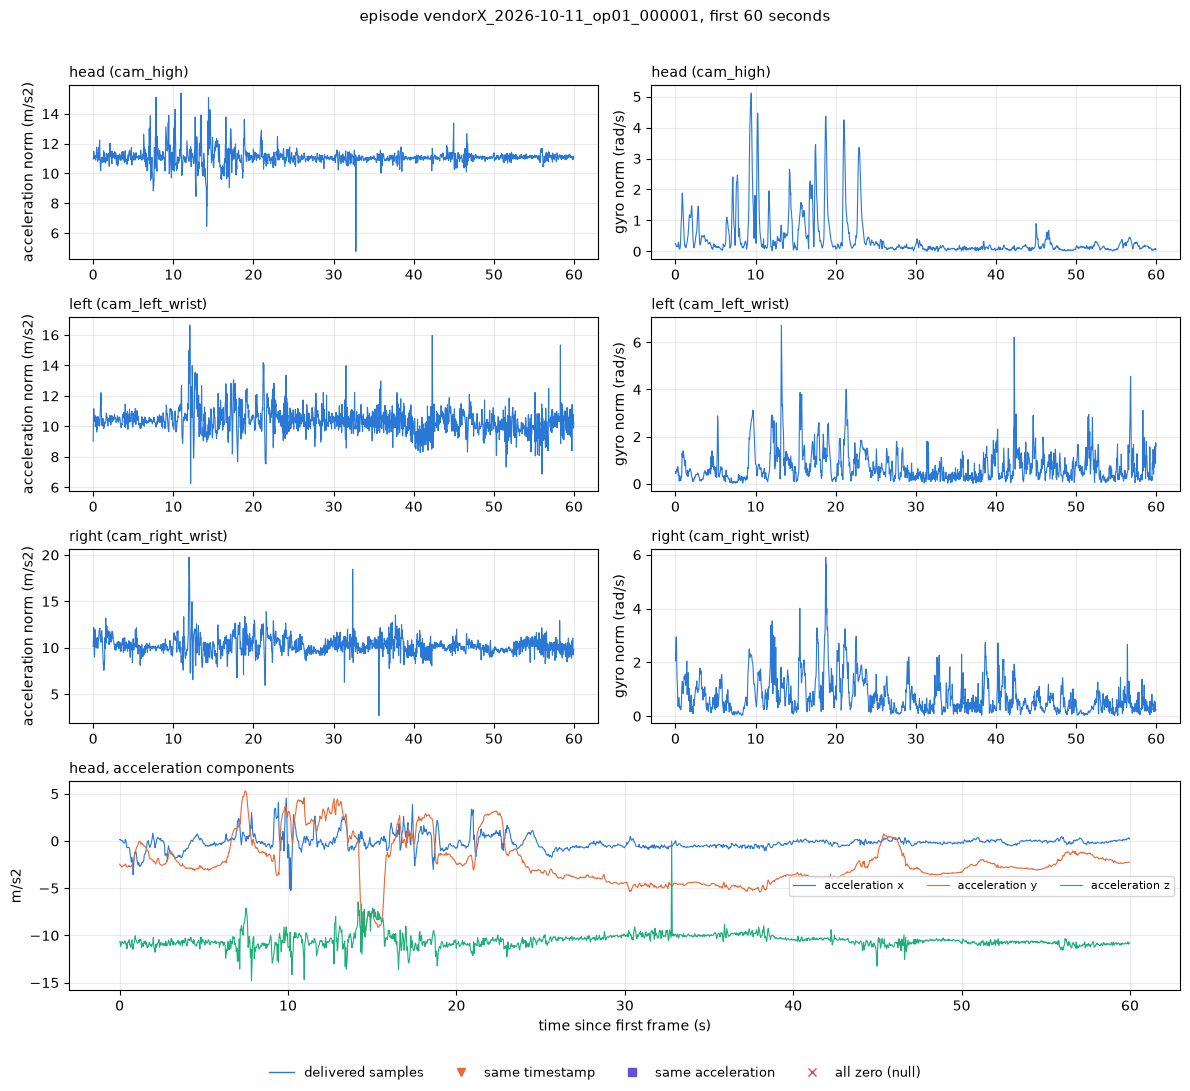

In [12]:
with step("figure"):
    need("eps")
    ep1 = next(ep for ep in ep_ids if ep in eps and eps[ep]["ok"])
    cams1 = eps[ep1]["cams"]
    t0 = min(int(cams1[c]["utc"][0]) for c in BODY)
    blue, orange, violet, red, aqua = "#2a78d6", "#eb6834", "#6250d6", "#e34948", "#1baf7a"
    marks = [(1, "same timestamp", orange, "v"), (2, "same acceleration", violet, "s"), (4, "all zero (null)", red, "x")]
    fig = plt.figure(figsize=(12, 11))
    grid = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 1.2])
    for r, cam in enumerate(BODY):
        c = cams1[cam]
        t = (c["utc"] - t0) / 1e9
        m = t <= 60
        zero = (c["flags"] & 4) > 0
        acc = c["acc"].astype(float)
        gyro = c["gyro"].astype(float)
        acc[zero] = np.nan
        gyro[zero] = np.nan
        for col, (vals, label) in enumerate([(np.linalg.norm(acc, axis=1), "acceleration norm (m/s2)"),
                                             (np.linalg.norm(gyro, axis=1), "gyro norm (rad/s)")]):
            ax = fig.add_subplot(grid[r, col])
            ax.plot(t[m], vals[m], lw=0.8, color=blue, label="delivered samples")
            for bit, name, colr, mk in marks:
                f = ((c["flags"] & bit) > 0) & m
                if not f.any():
                    continue
                if bit == 4:
                    ax.plot(t[f], np.zeros(int(f.sum())), mk, color=colr, ms=6, label=name, transform=ax.get_xaxis_transform(), clip_on=False)
                else:
                    ax.plot(t[f], vals[f], mk, color=colr, ms=5, ls="none", label=name)
            ax.set_title(f"{DEVICE[cam]} ({cam})", fontsize=10, loc="left")
            ax.set_ylabel(label)
            ax.grid(alpha=0.25)
    ax = fig.add_subplot(grid[3, :])
    c = cams1["cam_high"]
    t = (c["utc"] - t0) / 1e9
    m = t <= 60
    acc = c["acc"].astype(float)
    acc[(c["flags"] & 4) > 0] = np.nan
    for k, (name, colr) in enumerate([("x", blue), ("y", orange), ("z", aqua)]):
        ax.plot(t[m], acc[m, k], lw=0.8, color=colr, label=f"acceleration {name}")
    ax.set_title("head, acceleration components", fontsize=10, loc="left")
    ax.set_xlabel("time since first frame (s)")
    ax.set_ylabel("m/s2")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=3, loc="center right")
    handles = [Line2D([], [], color=blue, lw=1, label="delivered samples")]
    handles += [Line2D([], [], color=colr, marker=mk, ls="none", ms=6, label=name) for _, name, colr, mk in marks]
    fig.legend(handles=handles, ncol=4, loc="lower center", fontsize=9, frameon=False)
    fig.suptitle(f"episode {ep1}, first 60 seconds", fontsize=11)
    fig.tight_layout(rect=[0, 0.035, 1, 0.97])
    fig.savefig(REPORTS / "08e_imu_overview.png", dpi=150)
    plt.show()
    plt.close(fig)

## 11. hypothesis tests
Collects the checks of the earlier steps in one table.

In [13]:
with step("hypothesis tests"):
    tests = []

    def add(tid, text, measured, result):
        tests.append({"id": tid, "hypothesis": text, "measured": measured, "result": result})

    cdf = check_df if "check_df" in globals() and len(check_df) else pd.DataFrame()
    n_ep = len(ep_ids)

    def col_all(name, kind=None):
        if cdf.empty or name not in cdf.columns:
            return None
        d = cdf if kind is None else cdf[cdf["kind"] == kind]
        d = d[name]
        return int((d == True).sum()), int(len(d))

    def pf(ok):
        return "PASS" if ok else "FLAG"

    opened = [ep for ep in ep_ids if ep in scan and scan[ep]["opened"]]
    add("I1", "every file opens with the reader", f"{len(opened)} of {n_ep} files opened", pf(len(opened) == n_ep and n_ep > 0))

    seven = 0
    for ep in opened:
        top = scan[ep]["topics"]
        vid = [t for t in VIDEO_TOPIC.values() if t in top and top[t]["schema"] == "foxglove.CompressedVideo" and top[t]["msg_enc"] == "protobuf"]
        imu = [t for t in IMU_TOPIC.values() if t in top and top[t]["msg_enc"] == "json" and top[t]["schema_enc"] == "jsonschema"]
        if len(top) == 7 and len(vid) == 4 and len(imu) == 3:
            seven += 1
    add("I2", "seven channels per file (four video protobuf, three imu json)", f"{seven} of {n_ep} files", pf(seven == n_ep and n_ep > 0))

    def all_pass(tid, text, name, kind="imu"):
        r = col_all(name, kind)
        if r is None:
            add(tid, text, "not run", "FLAG")
        else:
            add(tid, text, f"{r[0]} of {r[1]} channels", pf(r[0] == r[1] and r[1] > 0))

    all_pass("I3", "imu message counts equal the frame counts of their camera", "chk_count_equals_frames")
    all_pass("I4", "every imu message has exactly the log_time of its video frame", "chk_log_time_equals_video")
    a = col_all("chk_nondecreasing")
    b = col_all("file_nondecreasing")
    if a is None or b is None:
        add("I5", "log times non-decreasing in file order and per channel", "not run", "FLAG")
    else:
        add("I5", "log times non-decreasing in file order and per channel", f"{a[0]} of {a[1]} channels, {b[0]} of {b[1]} rows with file order ok", pf(a[0] == a[1] and b[0] == b[1] and a[1] > 0))
    v500 = col_all("chk_values_equal_500", "imu")
    vnull = col_all("chk_null_iff_zero", "imu")
    vall = col_all("chk_values_equal_all", "imu")
    if v500 is None or vnull is None:
        add("I6", "imu values equal the source (500 samples per channel) and null iff all zero", "not run", "FLAG")
    else:
        add("I6", "imu values equal the source (500 samples per channel) and null iff all zero",
            f"values {v500[0]} of {v500[1]} (all samples {vall[0]} of {vall[1]}), null iff zero {vnull[0]} of {vnull[1]}",
            pf(v500[0] == v500[1] and vnull[0] == vnull[1] and v500[1] > 0))
    if "flags_df" in globals() and len(flags_df):
        parts = []
        for ep, g in flags_df.groupby("episode_id", sort=False):
            parts.append(f"{ep}: ts {int(g['same_timestamp'].sum())}, acc {int(g['same_acceleration'].sum())}, zero {int(g['all_zero'].sum())}")
        add("I7", "flag counts per episode (info)", " | ".join(parts), "INFO")
    else:
        add("I7", "flag counts per episode (info)", "not run", "INFO")
    ok8 = 0
    for ep in opened:
        r = cdf[cdf["episode_id"] == ep].iloc[0] if not cdf.empty and (cdf["episode_id"] == ep).any() else None
        if r is not None and r["metadata_record_ok"] and r["metadata_keys_ok"] and r["metadata_tags_ok"] and len(required_keys.get(ep, [])) == 17:
            ok8 += 1
    counts8 = sorted({len(v) for v in required_keys.values()})
    add("I8", "the metadata record has all 17 required keys as strings and episode_tags does not contain hand_pose",
        f"{ok8} of {n_ep} files, required key counts {counts8}", pf(ok8 == n_ep and n_ep > 0))
    vid_ids = cdf[cdf["kind"] == "video"] if not cdf.empty else cdf
    if len(vid_ids):
        n_h = int((vid_ids["chk_h264_identical"] == True).sum())
        n_r = int((vid_ids["chk_records_equal_v1_1"] == True).sum())
        n_m = int((vid_ids["chk_messages_equal_v1_1"] == True).sum())
        add("I9", "reassembled video streams are byte-identical to the .h264 files and the video channels equal those of v1.1",
            f"{n_h} of {len(vid_ids)} streams identical, records equal v1.1 {n_r} of {len(vid_ids)}, messages equal v1.1 {n_m} of {len(vid_ids)}",
            pf(n_h == len(vid_ids) and n_r == len(vid_ids) and n_m == len(vid_ids)))
    else:
        add("I9", "reassembled video streams are byte-identical to the .h264 files and the video channels equal those of v1.1", "not run", "FLAG")
    if "man" in globals() and len(man):
        gb = man["size_gb"].sum()
        hours = man["duration_s"].sum() / 3600
        added = man["imu_bytes_added"].dropna().sum()
        add("I10", "total size, bytes added by the imu and GB per hour (info)",
            f"{gb:.3f} GB total, {added / 1e6:.1f} MB added by imu, {gb / hours:.2f} GB per hour" if hours else f"{gb:.3f} GB total", "INFO")
    else:
        add("I10", "total size, bytes added by the imu and GB per hour (info)", "not run", "INFO")
    if cli_state["found"]:
        add("I11", "mcap command line tool and doctor (info)", "doctor ok" if cli_state["doctor_ok"] else "doctor reported a problem, see 08e_mcap_cli.txt", "INFO")
    else:
        add("I11", "mcap command line tool and doctor (info)", "mcap tool not found on PATH", "INFO")
    tests_df = pd.DataFrame(tests)
    tests_df.to_csv(REPORTS / "08e_hypothesis_check.csv", index=False)
    with pd.option_context("display.max_colwidth", 120):
        for t in tests:
            print(f"{t['id']:4} {t['result']:5} {t['hypothesis']}")
            print(f"           measured: {t['measured']}")

I1   PASS  every file opens with the reader
           measured: 4 of 4 files opened
I2   PASS  seven channels per file (four video protobuf, three imu json)
           measured: 4 of 4 files
I3   PASS  imu message counts equal the frame counts of their camera
           measured: 12 of 12 channels
I4   PASS  every imu message has exactly the log_time of its video frame
           measured: 12 of 12 channels
I5   PASS  log times non-decreasing in file order and per channel
           measured: 28 of 28 channels, 28 of 28 rows with file order ok
I6   PASS  imu values equal the source (500 samples per channel) and null iff all zero
           measured: values 12 of 12 (all samples 12 of 12), null iff zero 12 of 12
I7   INFO  flag counts per episode (info)
           measured: vendorX_2026-10-11_op01_000001: ts 0, acc 0, zero 1 | vendorX_2026-10-11_op01_000002: ts 0, acc 0, zero 1 | vendorX_2026-10-11_op01_000003: ts 0, acc 1, zero 0 | vendorX_2026-10-11_op01_000004: ts 4, acc 4, zero 0
I

## 12. summary and share zip
Saves the summary json and puts the 08e reports and the final metadata into reports\share_08e.zip.

In [14]:
with step("summary and zip"):
    need("tests_df")
    summary = {
        "run_utc": datetime.now(timezone.utc).isoformat(),
        "elapsed_s": round(time.time() - T_START, 1),
        "notebook": NB_NAME,
        "force": FORCE,
        "final_keys_only": FINAL_KEYS_ONLY,
        "versions": VERSIONS,
        "episodes": ep_ids,
        "build_status": {ep: v.get("status") for ep, v in build_info.items()},
        "files": int(len(man)) if "man" in globals() else 0,
        "total_size_bytes": int(man["size_bytes"].sum()) if "man" in globals() and len(man) else None,
        "total_duration_s": float(man["duration_s"].sum()) if "man" in globals() and len(man) else None,
        "imu_messages": int(sum(man[f"imu_{d}"].sum() for d in DEVICE.values())) if "man" in globals() and len(man) else None,
        "flag_totals": {k: int(flags_df[k].sum()) for k in ("same_timestamp", "same_acceleration", "all_zero")} if "flags_df" in globals() and len(flags_df) else None,
        "lag_s_06": lag_a if "lag_a" in globals() else None,
        "lag_s_08b": lag_b if "lag_b" in globals() else None,
        "tests": tests_df.to_dict(orient="records"),
    }
    (REPORTS / "08e_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    zip_path = REPORTS / "share_08e.zip"
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(REPORTS.glob("08e_*")):
            if p.is_file():
                z.write(p, p.name)
        for ep, meta in meta_final.items():
            z.writestr(f"metadata_final/{ep}.json", json.dumps(meta, indent=2))
    print("episodes:", len(ep_ids), "| files read back:", len(scan))
    for t in tests:
        print(t["id"], t["result"])
    print("zip:", zip_path)

episodes: 4 | files read back: 4
I1 PASS
I2 PASS
I3 PASS
I4 PASS
I5 PASS
I6 PASS
I7 INFO
I8 PASS
I9 PASS
I10 INFO
I11 INFO
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_08e.zip
